# The transition function, step by step

This notebook shows how to load **P(s′ | s, a)**, the month-to-month transition function of the Financial Twin MDP, and what it does.

| Section | You learn |
|---|---|
| 1. Load | What is inside the model file, and where each piece comes from |
| 2. State and actions | How a person's situation and choices are encoded |
| 3. One month as probabilities | `outcome_probs(s, a)`: every possible next situation and its probability |
| 4. The learned pieces | What the simulated job, study and housing markets taught the model |
| 5. One sampled month | `sample(s, a, rng)`: a random next month, with every franc accounted for |
| 6. A whole life | Rolling Alexia forward 10 years under two different choices |
| 7. Uncertainty | How sure the model is about its own numbers |
| 8. How good is it? | Comparison with Swiss statistics and transfer tests |

**Kernel:** `Python (lauzhack-sim)` (the environment `~/envs/lauzhack-sim`). Runs in about a minute.
**Rebuild the model:** `python -m twin_game_theory.world.build` · **Tests:** `python -m twin_game_theory.world.test_transition`

All data is synthetic, and every assumption is labelled. Nothing here is a forecast or financial advice.

In [1]:
import sys
from dataclasses import asdict, replace
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "twin_game_theory").exists() and ROOT != ROOT.parent:   # find the repo root from wherever Jupyter starts
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from twin_game_theory.world import spec as sp
from twin_game_theory.world.transition import DISCRETE, Action, State, TransitionModel, alexia

# Chart style: thin marks, recessive grid, text in ink colours (not series colours)
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "legend.frameon": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110,
})
pd.set_option("display.max_colwidth", 100)

REGIME = ["normal", "inflation", "recession"]
HOUSING = ["shared flat", "small flat", "family flat"]
HOUSEHOLD = ["single", "couple", "family"]
LIFESTYLE = ["lean", "standard", "comfortable"]


def describe(s: State) -> pd.Series:
    """A state in words."""
    return pd.Series({
        "month": f"{s.t} (age {s.age:.1f})",
        "work status W": sp.W_NAMES[s.W] + (f", studying for a {sp.EDU_NAMES[s.prog]}" if s.W == sp.S else ""),
        "highest degree": sp.EDU_NAMES[s.edu],
        "pay level k": f"{s.k} (full-time CHF {sp.PAY[s.k - 1]:,.0f})",
        "months without work u": s.u,
        "pending": sp.PEND_NAMES[s.pend] + (f" at level {s.offer_k}" if s.pend == sp.P_JOB_OFFER else ""),
        "housing H / household F": f"{HOUSING[s.H]} / {HOUSEHOLD[s.F]}",
        "lifestyle L": LIFESTYLE[s.L],
        "economy M": REGIME[s.M],
        "cash C / investments I": f"CHF {s.C:,.0f} / CHF {s.I:,.0f}",
        "context": f"{s.city}, grades {s.grades:+.1f}, {s.apps} applications a month",
    }, name="value")


def changes(key, s: State) -> str:
    """What differs between a next-state key and the current state, in words (u is left out: it just ticks)."""
    d = dict(zip(DISCRETE, key))
    out = []
    if d["W"] != s.W:
        out.append(f"status {sp.W_NAMES[s.W]} → {sp.W_NAMES[d['W']]}")
    if d["edu"] != s.edu:
        out.append(f"graduated ({sp.EDU_NAMES[d['edu']]})")
    if d["prog"] != s.prog and d["W"] == sp.S:
        out.append(f"starts a {sp.EDU_NAMES[d['prog']]}")
    if d["k"] != s.k:
        out.append(f"pay level {s.k} → {d['k']}")
    if d["pend"] != s.pend:
        out.append("job offer at level %d (CHF %s)" % (d["offer_k"], f"{sp.PAY[d['offer_k'] - 1]:,.0f}")
                   if d["pend"] == sp.P_JOB_OFFER else f"pending: {sp.PEND_NAMES[s.pend]} → {sp.PEND_NAMES[d['pend']]}")
    if d["H"] != s.H:
        out.append(f"moves: {HOUSING[s.H]} → {HOUSING[d['H']]}")
    if d["F"] != s.F:
        out.append(f"household: {HOUSEHOLD[s.F]} → {HOUSEHOLD[d['F']]}")
    if d["L"] != s.L:
        out.append(f"lifestyle → {LIFESTYLE[d['L']]}")
    if d["M"] != s.M:
        out.append(f"economy → {REGIME[d['M']]}")
    return "; ".join(out) or "nothing changes (besides the clock)"


def outcomes(s: State, a: Action, top=8) -> pd.DataFrame:
    """outcome_probs as a readable table."""
    probs = model.outcome_probs(s, a)
    rows = [(p, changes(k, s)) for k, p in probs.items()]
    df = pd.DataFrame(rows, columns=["probability", "what happens next month"])
    df = df.groupby("what happens next month", as_index=False).probability.sum().sort_values("probability", ascending=False)
    return df.head(top).style.format({"probability": "{:.1%}"}).hide(axis="index")

## 1. Load the model

`TransitionModel()` reads `twin_game_theory/world/world_model.json`. That file is produced by `python -m twin_game_theory.world.build`, which:

1. **Calibrates** a simulated society (1,000 people, three markets) to Swiss statistics.
2. **Simulates** societies of three sizes (200, 1,000 and 2,000 people; 90,000 people in all) for 120 months. Mixing sizes stops the model from learning the quirks of one market size.
3. **Learns** the market probabilities from what happened.
4. **Validates** the result on societies it never saw, including 5,000-person societies, which are larger than any in training.

In [2]:
model = TransitionModel()
wm = model.wm
print("built:", wm["built"])
pieces = pd.DataFrame([
    ("P(job offer) and the offered pay level", "learned from the simulated world", f"{wm['markets']['job_offer']['rows']:,} searching months"),
    ("P(admitted to a master's or PhD)", "learned from the simulated world", f"{wm['markets']['admission']['rows']:,} applications"),
    ("P(getting a bigger or smaller flat)", "learned from the simulated world", f"{wm['markets']['flat']['rows']:,} flat applications"),
    ("job loss, promotion, partner, child, separation, economy, returns", "priors from the MDP spec", "spec.py"),
    ("hours changes approved, study durations", "assumptions (ours)", "spec.py"),
    ("pay, rent, living costs, bills, bonus, noise", "fitted on the challenge ledger", "calibration.json"),
    ("cash, investments, credit", "exact bookkeeping", "transition.py"),
], columns=["piece of P(s'|s,a)", "source", "evidence"])
pieces.style.hide(axis="index")

built: 2026-11-21 22:27


"piece of P(s'|s,a)",source,evidence
P(job offer) and the offered pay level,learned from the simulated world,"289,576 searching months"
P(admitted to a master's or PhD),learned from the simulated world,"27,000 applications"
P(getting a bigger or smaller flat),learned from the simulated world,"144,505 flat applications"
"job loss, promotion, partner, child, separation, economy, returns",priors from the MDP spec,spec.py
"hours changes approved, study durations",assumptions (ours),spec.py
"pay, rent, living costs, bills, bonus, noise",fitted on the challenge ledger,calibration.json
"cash, investments, credit",exact bookkeeping,transition.py


The **calibrated knobs** are the few world settings tuned so the simulated society behaves like Switzerland. The rest are assumptions:

In [3]:
k = wm["knobs"]
pd.DataFrame({
    "value": [k["openings"], k["b_master"], k["b_phd"], k["phd_seats"], k["master_seats"], k["flat_turnover"], k["student_share"]],
    "meaning": ["job openings a month per labour-force member", "preference for a master's (persona score bonus)",
                "preference for a PhD", "PhD positions a year per person", "master places a year per person (ample)",
                "flats re-let a month per flat (Swiss moving rate 9.3%/yr)", "share of students in each society"],
    "how set": ["calibrated", "calibrated", "calibrated", "calibrated", "assumed", "Swiss statistic", "assumed"],
}, index=["openings", "b_master", "b_phd", "phd_seats", "master_seats", "flat_turnover", "student_share"]).round(4)

,value,meaning,how set
openings,0.0129,job openings a month per labour-force member,calibrated
b_master,16.0000,preference for a master's (persona score bonus),calibrated
b_phd,1.0000,preference for a PhD,calibrated
phd_seats,0.0120,PhD positions a year per person,calibrated
master_seats,0.2500,master places a year per person (ample),assumed
flat_turnover,0.0078,flats re-let a month per flat (Swiss moving rate 9.3%/yr),Swiss statistic
student_share,0.0800,share of students in each society,assumed


## 2. State and actions

A **state** `s` is everything the next month depends on (Markov). Alexia is the challenge's example person: 20, finishing a bachelor's in Lausanne, CHF 8,000 in savings.

In [4]:
s0 = alexia()
describe(s0).to_frame()

,value
month,0 (age 20.0)
work status W,"S, studying for a bachelor"
highest degree,none
pay level k,"1 (full-time CHF 4,500)"
months without work u,0
pending,none
housing H / household F,shared flat / single
lifestyle L,standard
economy M,normal
cash C / investments I,"CHF 8,000 / CHF 0"


An **action** `a = Action(status, housing, spending, assets)` has four parts, chosen together each month:

| part | options |
|---|---|
| `status` | `stop`, `minus` (fewer hours), `stay`, `plus` (search for a job / more hours), `apply_master`, `apply_phd`, `accept` (an offer) |
| `housing` | -1, 0, +1 tier |
| `spending` | -1, 0, +1 lifestyle tier |
| `assets` | -1 sell to refill a 3-month buffer, 0 hold, +1 invest cash above the buffer |

`model.allowed(s)` lists what is allowed. While she is studying, Alexia can keep studying (`stay`) or start searching (`plus`):

In [5]:
model.allowed(s0)

{'status': ['stay', 'plus'],
 'housing': [0, 1],
 'spending': [-1, 0, 1],
 'assets': [0, 1]}

Here is the situation that matters most: **Alexia has just graduated.** She now has a bachelor's, no job, and has been out of work for one month. More options open up, including applying for a master's:

In [6]:
grad = replace(s0, W=sp.N, prog=sp.NONE, edu=sp.BACHELOR, u=1)
display(describe(grad).to_frame())
model.allowed(grad)

,value
month,0 (age 20.0)
work status W,N
highest degree,bachelor
pay level k,"1 (full-time CHF 4,500)"
months without work u,1
pending,none
housing H / household F,shared flat / single
lifestyle L,standard
economy M,normal
cash C / investments I,"CHF 8,000 / CHF 0"


{'status': ['stay', 'plus', 'apply_master'],
 'housing': [0, 1],
 'spending': [-1, 0, 1],
 'assets': [0, 1]}

## 3. One month as probabilities: `outcome_probs(s, a)`

For a state and an action, `outcome_probs` returns the **exact probability of every possible next discrete situation**: work status, degree, pay level, pending offers, housing, household, lifestyle and economy. Cash and investments are continuous, so they come from `sample` (section 5).

**Option A: she searches for a job.** Offers come from the job market, which was learned from the simulated world:

In [7]:
outcomes(grad, Action("plus"))

what happens next month,probability
nothing changes (besides the clock),74.3%
"job offer at level 1 (CHF 4,500)",19.4%
"job offer at level 2 (CHF 6,100)",4.9%
economy → recession,0.5%
economy → inflation,0.4%
household: single → couple,0.3%
"job offer at level 1 (CHF 4,500); economy → inflation",0.1%
"job offer at level 1 (CHF 4,500); household: single → couple",0.1%


**Option B: she applies for a master's.** Admission comes from the study-place market. Places are ample, as they are for Swiss bachelor's holders:

In [8]:
outcomes(grad, Action("apply_master"))

what happens next month,probability
pending: none → admitted_master,98.4%
pending: none → admitted_master; economy → inflation,0.5%
pending: none → admitted_master; economy → recession,0.5%
pending: none → admitted_master; household: single → couple,0.4%
nothing changes (besides the clock),0.2%
pending: none → admitted_master; household: single → couple; economy → inflation,0.0%
pending: none → admitted_master; household: single → couple; economy → recession,0.0%
economy → inflation,0.0%


**Option C: she searches *and* tries to move to a small flat.** The landlord's rule requires rent ≤ 1/3 of income, or savings worth 12 months of rent. With CHF 530 of benefits and CHF 8,000 in cash she fails it, so the move has probability 0:

In [9]:
outcomes(grad, Action("plus", housing=+1))

what happens next month,probability
nothing changes (besides the clock),74.3%
"job offer at level 1 (CHF 4,500)",19.4%
"job offer at level 2 (CHF 6,100)",4.9%
economy → recession,0.5%
economy → inflation,0.4%
household: single → couple,0.3%
"job offer at level 1 (CHF 4,500); economy → inflation",0.1%
"job offer at level 1 (CHF 4,500); household: single → couple",0.1%


The probabilities move with the situation. This is **P(job offer this month)** for the same searcher under different degrees and economic conditions:

In [10]:
rows = []
for edu in (sp.BACHELOR, sp.MASTER, sp.PHD):
    for M in (sp.NORMAL, sp.RECESSION):
        d = asdict(replace(grad, edu=edu, M=M))
        rows.append((sp.EDU_NAMES[edu], REGIME[M], model.p_job_offer(d)))
pd.DataFrame(rows, columns=["degree", "economy", "P(offer)"]).pivot(index="degree", columns="economy", values="P(offer)") \
  .loc[["bachelor", "master", "phd"], ["normal", "recession"]].style.format("{:.1%}")

economy,normal,recession
degree,,
bachelor,24.6%,4.1%
master,36.8%,7.1%
phd,48.7%,11.0%


## 4. The learned pieces

Each market model is a small, readable formula fitted on the simulated world's logs. The job offer uses the complementary log-log model from `analysis/society_sim/MATH.md`:

$$P(\text{offer}) = 1 - \exp\big(-\exp(\beta^\top x)\big)$$

Here $x$ includes **log tightness θ** (openings per application). The twin doesn't see θ directly: the model **averages over the tightness the world produced** in that economy. Below are the coefficients, with their spread across 5 bootstrap refits:

In [11]:
def coef_table(name):
    m = wm["markets"][name]
    draws = np.array(m["coef_draws"])
    return pd.DataFrame({"coefficient": m["coef"], "bootstrap sd": draws.std(0)}, index=m["features"]).round(3)

display(coef_table("job_offer").T)
display(coef_table("admission").T)
display(coef_table("flat").T)

,const,edu_bachelor,edu_master,edu_phd,grades,u_years,k_minus_1,log_apps,log_theta,inflation,recession,student
coefficient,-0.309,0.458,1.045,1.530,0.537,-0.632,0.157,0.935,0.914,0.022,-0.344,0.045
bootstrap sd,0.011,0.016,0.014,0.043,0.009,0.018,0.006,0.017,0.009,0.045,0.036,0.011


,const,phd,grades,log_theta
coefficient,3.383,-0.133,1.429,3.611
bootstrap sd,0.059,0.081,0.024,0.070


,const,to_small,to_family,downsizing,log_income_over_rent,log_theta
coefficient,-0.680,0.728,1.384,0.008,1.872,2.266
bootstrap sd,0.041,0.022,0.042,0.015,0.018,0.009


How to read them:
- **Job offers**
  - Positive means a higher chance. A master's adds more than a bachelor's, and good grades help.
  - Each year without work lowers the chance (`u_years` < 0).
  - `log_apps` and `log_theta` are close to 1, as matching theory predicts. Twice the applications, or twice the openings per application, roughly doubles the hazard.
- **Admission:** grades dominate.
- **Flats:** income relative to rent dominates.

The charts make this concrete.

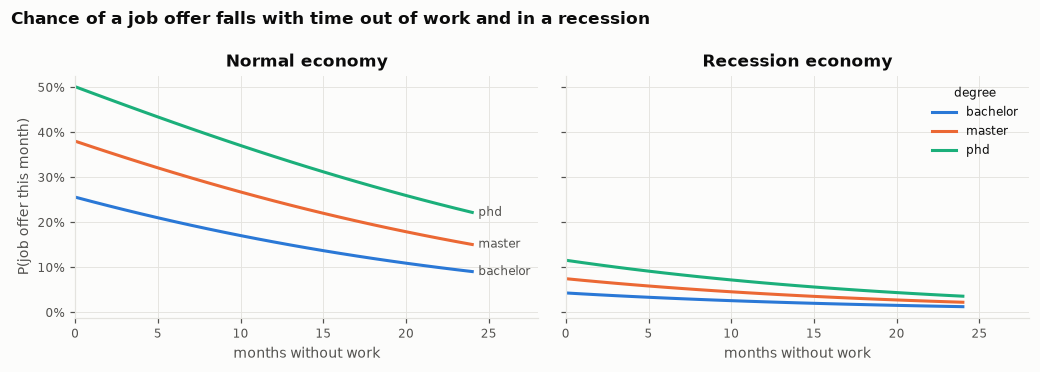

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
months = np.arange(0, 25)
for ax, M in zip(axes, (sp.NORMAL, sp.RECESSION)):
    for edu, color in ((sp.BACHELOR, BLUE), (sp.MASTER, ORANGE), (sp.PHD, AQUA)):
        p = [model.p_job_offer(asdict(replace(grad, edu=edu, u=int(u), M=M))) for u in months]
        ax.plot(months, p, color=color, label=sp.EDU_NAMES[edu])
        if M == sp.NORMAL:                       # direct labels where the lines are apart; the legend covers the right panel
            ax.annotate(sp.EDU_NAMES[edu], (months[-1], p[-1]), xytext=(4, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK2)
    ax.set_title(f"{REGIME[M].capitalize()} economy")
    ax.set_xlabel("months without work")
    ax.set_xlim(0, 28)
axes[0].set_ylabel("P(job offer this month)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(loc="upper right", title="degree", title_fontsize=8)
fig.suptitle("Chance of a job offer falls with time out of work and in a recession", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

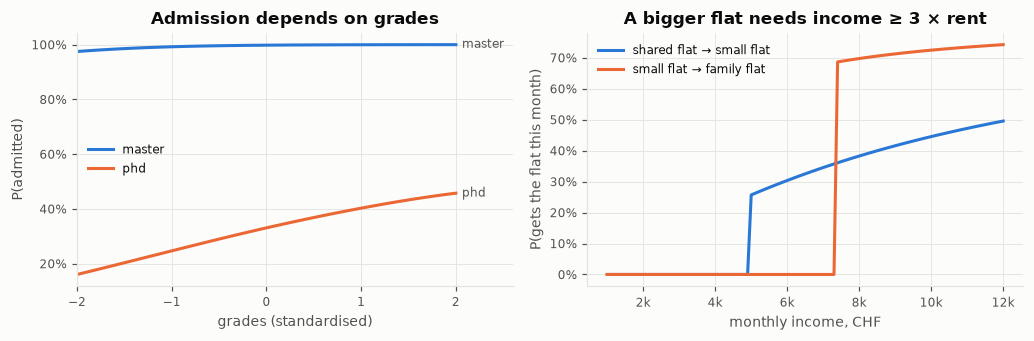

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))
g = np.linspace(-2, 2, 41)
for prog, color in ((sp.MASTER, BLUE), (sp.PHD, ORANGE)):
    p = [model.p_admission(asdict(replace(grad, grades=float(x))), prog) for x in g]
    axes[0].plot(g, p, color=color, label=sp.EDU_NAMES[prog])
    axes[0].annotate(sp.EDU_NAMES[prog], (g[-1], p[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
axes[0].set_title("Admission depends on grades")
axes[0].set_xlabel("grades (standardised)")
axes[0].set_ylabel("P(admitted)")
axes[0].set_xlim(-2, 2.6)
axes[0].legend(loc="center left")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

inc = np.linspace(1000, 12000, 111)
for (frm, to), color in (((0, 1), BLUE), ((1, 2), ORANGE)):
    p = [model.p_flat(asdict(replace(grad, H=frm, W=sp.E100, C=5000.0)), to, x) for x in inc]
    lab = f"{HOUSING[frm]} → {HOUSING[to]}"
    axes[1].plot(inc, p, color=color, label=lab)
axes[1].set_title("A bigger flat needs income ≥ 3 × rent")
axes[1].set_xlabel("monthly income, CHF")
axes[1].set_ylabel("P(gets the flat this month)")
axes[1].legend(loc="upper left")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
fig.tight_layout()

The jump in the flat chart is the landlord's income rule, a deterministic eligibility test. Above it, competition decides: flats are scarce, which matches the 1% Swiss vacancy rate.

## 5. One sampled month: `sample(s, a, rng)`

`sample` draws one random next state, including **cash and investments**, and returns a **ledger** of every flow. The order follows the MDP spec:

1. apply the action;
2. economy and chance events;
3. market outcomes;
4. money.

In [14]:
rng = np.random.default_rng(42)
s1, ledger = model.sample(grad, Action("plus"), rng)
display(pd.Series(ledger, name="CHF this month").round(0).to_frame())
flows = sum(v for k, v in ledger.items() if k != "market_return")
print(f"cash identity: {grad.C:,.0f} + {flows:,.0f} = {grad.C + flows:,.0f}  (model says {s1.C:,.0f})")
describe(s1).to_frame()

,CHF this month
income,531.0
bonus,0.0
rent,-1126.0
living,-1552.0
child,0.0
tuition,0.0
loan,0.0
bills,0.0
noise,199.0
moving,0.0


cash identity: 8,000 + -1,949 = 6,051  (model says 6,051)


,value
month,1 (age 20.1)
work status W,N
highest degree,bachelor
pay level k,"1 (full-time CHF 4,500)"
months without work u,2
pending,none
housing H / household F,shared flat / single
lifestyle L,standard
economy M,normal
cash C / investments I,"CHF 6,051 / CHF 0"


`sample` and `outcome_probs` walk **the same stages**, so they cannot disagree. Here is a check: 5,000 samples against the exact probabilities.

In [15]:
exact = model.outcome_probs(grad, Action("plus"))
def key(state):
    return tuple(getattr(state, k) for k in DISCRETE)

counts = pd.Series([key(model.sample(grad, Action("plus"), rng)[0]) for _ in range(5000)]).value_counts(normalize=True)
cmp = pd.DataFrame({"exact": pd.Series(exact), "sampled": counts}).fillna(0)
cmp.index = [changes(k, grad) for k in cmp.index]
cmp = cmp.groupby(level=0).sum().sort_values("exact", ascending=False).head(6)
print(f"total variation distance: {0.5 * (cmp.exact - cmp.sampled).abs().sum():.3f}")
cmp.style.format("{:.1%}")

total variation distance: 0.004


,exact,sampled
nothing changes (besides the clock),74.3%,73.9%
"job offer at level 1 (CHF 4,500)",19.4%,19.5%
"job offer at level 2 (CHF 6,100)",4.9%,5.1%
economy → recession,0.5%,0.5%
economy → inflation,0.4%,0.4%
household: single → couple,0.3%,0.4%


## 6. A whole life: rolling Alexia forward 10 years

A transition function plus a **policy** gives a life. The real persona policy is another teammate's piece, so here are two **placeholder rules** that differ in a single choice:
- **Work first:** after the bachelor's, search for a job and accept the first offer.
- **Master's first:** after the bachelor's, apply for a master's; after it, search and accept the first offer.

Both see **the same luck**: path *i* uses the same random seed under both rules (common random numbers), so the differences come from the choice. 300 lives per rule.

In [16]:
def policy_factory(master_first: bool):
    def policy(s: State) -> Action:
        allowed = model.allowed(s)["status"]
        if s.pend in (sp.P_JOB_OFFER, sp.P_ADMIT_MASTER):
            want = "accept" if (s.pend == sp.P_JOB_OFFER or master_first) else "stay"
        elif s.W == sp.N and master_first and s.edu == sp.BACHELOR and s.pend == sp.P_NONE:
            want = "apply_master"
        elif s.W == sp.N and s.pend == sp.P_NONE:
            want = "plus"
        else:
            want = "stay"
        return Action(want if want in allowed else "stay")
    return policy


def rollout(policy, n_paths=300, months=120, seed=0):
    nw, status, master = np.zeros((n_paths, months + 1)), np.zeros((n_paths, months + 1), int), np.zeros(n_paths, bool)
    breach = np.zeros(n_paths, bool)
    for i in range(n_paths):
        rng, s = np.random.default_rng([seed, i]), alexia()
        nw[i, 0], status[i, 0] = s.C + s.I, s.W
        for t in range(months):
            s, _ = model.sample(s, policy(s), rng)
            nw[i, t + 1], status[i, t + 1] = s.C + s.I, s.W
        master[i], breach[i] = s.edu >= sp.MASTER, s.breach
    return dict(nw=nw, status=status, master=master, breach=breach)


import time
t0 = time.time()
runs = {"work first": rollout(policy_factory(False)), "master's first": rollout(policy_factory(True))}
print(f"simulated {2 * 300 * 120:,} months in {time.time() - t0:.0f} s")

simulated 72,000 months in 18 s


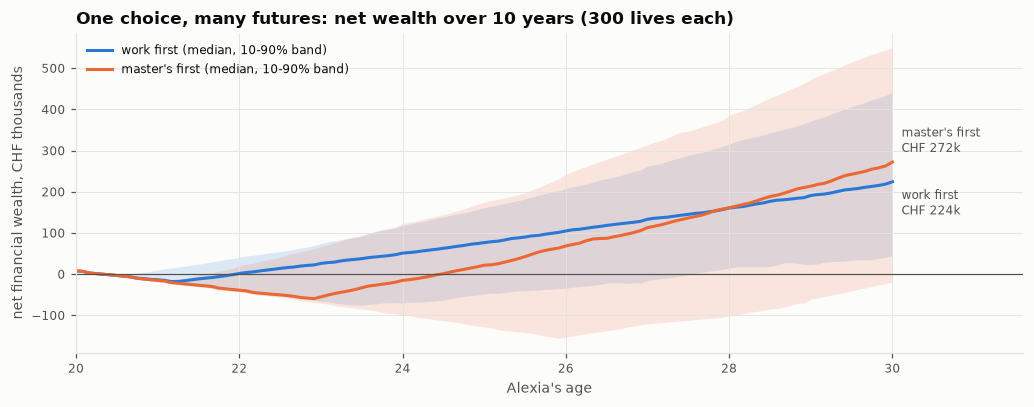

In [17]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
age = 20 + np.arange(121) / 12
ends = []
for (name, r), color in zip(runs.items(), (BLUE, ORANGE)):
    lo, med, hi = np.percentile(r["nw"], [10, 50, 90], axis=0) / 1000
    ax.fill_between(age, lo, hi, color=color, alpha=0.15, linewidth=0)
    ax.plot(age, med, color=color, label=f"{name} (median, 10-90% band)")
    ends.append((name, med[-1]))
ends.sort(key=lambda e: e[1])
for j, (name, y) in enumerate(ends):                # lower series label nudged down, upper one up
    ax.annotate(f"{name}\nCHF {y:.0f}k", (age[-1], y), xytext=(6, -14 if j == 0 else 14), textcoords="offset points",
                va="center", fontsize=8, color=INK2)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xlim(20, 31.6)
ax.set_xlabel("Alexia's age")
ax.set_ylabel("net financial wealth, CHF thousands")
ax.set_title("One choice, many futures: net wealth over 10 years (300 lives each)", loc="left")
ax.legend(loc="upper left")
fig.tight_layout()

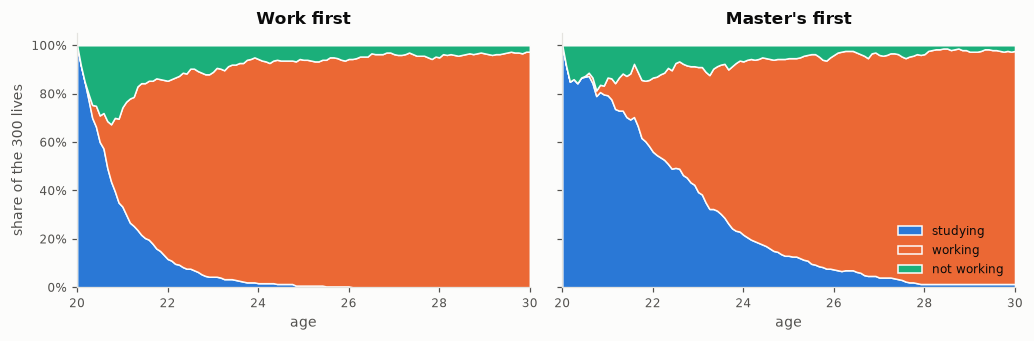

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
groups = [("studying", [sp.S], BLUE), ("working", [sp.E60, sp.E80, sp.E100], ORANGE), ("not working", [sp.N], AQUA)]
for ax, (name, r) in zip(axes, runs.items()):
    shares = [np.isin(r["status"], codes).mean(0) for _, codes, _ in groups]
    ax.stackplot(age, *shares, colors=[c for *_, c in groups], labels=[g for g, *_ in groups],
                 edgecolor=SURFACE, linewidth=1.0)
    ax.set_title(name.capitalize())
    ax.set_xlabel("age")
    ax.set_xlim(20, 30)
    ax.grid(False)
axes[0].set_ylabel("share of the 300 lives")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()

In [19]:
summary = pd.DataFrame({
    name: {
        "median net wealth at 30 (CHF)": f"{np.median(r['nw'][:, -1]):,.0f}",
        "10th-90th percentile at 30": f"{np.percentile(r['nw'][:, -1], 10):,.0f} to {np.percentile(r['nw'][:, -1], 90):,.0f}",
        "lowest median point (CHF)": f"{np.median(r['nw'], 0).min():,.0f}",
        "share holding a master's at 30": f"{r['master'].mean():.0%}",
        "share working at 30": f"{np.isin(r['status'][:, -1], [sp.E60, sp.E80, sp.E100]).mean():.0%}",
        "share that hit the credit limit (spec: episode ends)": f"{r['breach'].mean():.0%}",
    } for name, r in runs.items()})
summary

,work first,master's first
median net wealth at 30 (CHF),"224,163","272,035"
10th-90th percentile at 30,"44,853 to 442,658","-18,780 to 549,845"
lowest median point (CHF),"-18,090","-59,542"
share holding a master's at 30,0%,99%
share working at 30,97%,96%
share that hit the credit limit (spec: episode ends),94%,100%


**Why do almost all lives hit the credit limit?** It isn't the choice. Alexia's recorded student budget runs a deficit: CHF 1,200 of income against roughly CHF 2,700 of rent and living costs. Her ledger shows CHF −16,700 by December 2026. The spec's credit limit is 3 × monthly income, only CHF 3,600 for a student, so both paths cross it in the first year, before the choices even differ. The model flags it (`s.breach`), and the spec would end the episode there; we keep simulating so the whole path stays visible. Two consequences for the team: the persona policy needs to use the spending and housing levers, and the student credit limit (family support, student loans) deserves a second look.

Reading the rest: the master's costs two years of student income plus tuition, so wealth dips early. It buys a higher entry pay level later.

Whether it catches up by 30 depends on the assumptions:
- entry pay levels;
- how long the master's lasts (P_STUDY_END);
- how hiring treats degrees (learned).

That's exactly the trade-off the Explorer should show, **as a range of futures, not a single answer**. With placeholder policies, read this as a demonstration of the machinery, not as advice.

## 7. Uncertainty: how sure is the model about its own numbers?

There are two kinds:
- **Luck** (the bands above): different random draws of offers, bills and events.
- **Model uncertainty:** the learned coefficients come from a finite simulation. The model keeps 5 bootstrap refits, and `sample(..., draw=i)` or `p_job_offer(d, draw=i)` uses refit *i*. Giving each simulated life a different `draw` makes this uncertainty part of the fan.

In [20]:
d = asdict(grad)
rows = {"main fit": model.p_job_offer(d)} | {f"bootstrap {i}": model.p_job_offer(d, draw=i) for i in range(5)}
pd.Series(rows, name="P(job offer) for Alexia, just graduated").to_frame().style.format("{:.2%}")

,"P(job offer) for Alexia, just graduated"
main fit,24.62%
bootstrap 0,24.81%
bootstrap 1,24.27%
bootstrap 2,24.58%
bootstrap 3,24.86%
bootstrap 4,24.48%


## 8. How good is it?

**Against Swiss statistics.** The world is calibrated to some figures and only *checked* against others:

In [21]:
t = pd.DataFrame(wm["swiss_targets"]).T[["use", "target", "band", "world", "within_band", "source"]]
t

,use,target,band,world,within_band,source
unemployment_rate,calibrate job openings,0.028,"[0.025, 0.045]",0.0385,True,"SECO, registered unemployment, 2025 annual average 2.8%"
median_unemployment_months,calibrate job openings,6.5,"[5.0, 8.0]",3.4856,False,"BFS labour force survey (SAKE), median duration of unemployment 199 days, Q4 2025"
bachelor_to_master_within_24m,calibrate the preference for a master's,0.87,"[0.8, 0.92]",0.8423,True,BFS data cited by Avenir Suisse (2024): about 87%; BFS Bologna barometer: 88% average since 2004
master_to_phd_within_24m,calibrate PhD positions,0.15,"[0.1, 0.2]",0.1373,True,ASSUMPTION: no verified BFS figure found; replace with the BFS transitions table when available
graduate_unemployment_1y_master,check only,0.064,"[0.03, 0.1]",0.0603,True,"BFS graduate survey, UH master graduates one year after their degree (ILO), 2025: 6.4%"
graduate_unemployment_1y_bachelor,check only,0.049,"[0.02, 0.1]",0.2559,False,"BFS graduate survey, FH bachelor graduates one year after their degree (ILO), 2025: 4.9%"


**Transfer.** Does the learned model still predict well in societies it was not trained on? The numbers are calibration error (ECE, percentage points) and predicted vs observed rates:

In [22]:
rows = []
for test, markets in wm["validation"].items():
    for name, r in markets.items():
        rows.append((test, name, r["mean_pred"], r["mean_obs"], r["ece_pts"]))
v = pd.DataFrame(rows, columns=["test", "market", "predicted", "observed", "ECE (pts)"])
v.style.format({"predicted": "{:.1%}", "observed": "{:.1%}", "ECE (pts)": "{:.2f}"}).hide(axis="index")

test,market,predicted,observed,ECE (pts)
new_societies_200_people,job_offer,16.0%,16.6%,1.59
new_societies_200_people,admission,39.1%,39.1%,0.38
new_societies_200_people,flat,25.9%,25.9%,1.43
new_societies_1000_people,job_offer,17.1%,17.9%,2.19
new_societies_1000_people,admission,60.3%,59.9%,0.88
new_societies_1000_people,flat,40.4%,40.6%,1.56
new_societies_2000_people,job_offer,22.0%,22.3%,2.58
new_societies_2000_people,admission,70.3%,70.1%,1.51
new_societies_2000_people,flat,41.7%,41.4%,1.31
new_societies_5000_people,job_offer,26.2%,26.1%,3.01


**Does the world depend on its size?** The same calibrated knobs, run in societies of different sizes. Job-market figures are stable. The PhD share is not: a 200-person society has only about 2 PhD positions a year, and they come in lumps. This is why training mixes sizes.

In [23]:
by_size = pd.DataFrame(wm["moments_by_society_size"]).T
by_size.index = [f"{int(n):,} people" for n in by_size.index]
by_size.loc["Swiss target"] = [wm["swiss_targets"][k]["target"] for k in by_size.columns]
by_size.style.format({"unemployment_rate": "{:.1%}", "median_unemployment_months": "{:.1f}",
                      "bachelor_to_master_within_24m": "{:.0%}", "master_to_phd_within_24m": "{:.1%}"})

,unemployment_rate,median_unemployment_months,bachelor_to_master_within_24m,master_to_phd_within_24m
200 people,3.7%,3.4,86%,6.7%
"1,000 people",3.9%,3.5,84%,13.7%
"2,000 people",3.2%,2.9,83%,16.6%
Swiss target,2.8%,6.5,87%,15.0%


In [24]:
pd.Series(wm["direction_checks"], name="passes").to_frame()

,passes
job: a master's helps more than a bachelor's,True
job: better grades help,True
job: a long spell out of work hurts,True
job: more applications help,True
job: more openings per application help,True
admission: better grades help,True
admission: more places per applicant help,True
flat: higher income relative to rent helps,True
flat: more vacancies per applicant help,True


**Honest summary**
- **Good:**
  - Unemployment, bachelor's → master's, and master's graduates' unemployment are in the Swiss range.
  - Predictions hold on new societies of every training size (200 to 2,000 people) and on a different persona mix: calibration error under 3 points everywhere.
  - Even 5,000-person societies, larger than any in training, are predicted within about 3 points (job offers 26.2% predicted against 26.1% observed).
  - All direction checks pass. Cash and wealth identities hold exactly (`test_transition.py`).
- **Not yet:**
  - Spells without work are too short (median 3.5 months against 6.5).
  - Bachelor's graduates who skip the master's are unemployed too often (26% against 4.9%).
  - Unemployment is 3.9%, above SECO's 2.8% (inside the band that allows for the higher ILO measure).
- **Assumed:** the master's → PhD share (15%), entry pay by degree, study durations, persona preferences.

## 9. Try it yourself

Change anything below and re-run. For example: give Alexia better grades, put her in a recession, or make her a master's graduate who has been out of work for a year.

In [25]:
me = replace(grad, grades=1.0, M=sp.RECESSION)          # edit me
display(describe(me).to_frame())
outcomes(me, Action("plus"))

,value
month,0 (age 20.0)
work status W,N
highest degree,bachelor
pay level k,"1 (full-time CHF 4,500)"
months without work u,1
pending,none
housing H / household F,shared flat / single
lifestyle L,standard
economy M,recession
cash C / investments I,"CHF 8,000 / CHF 0"


what happens next month,probability
nothing changes (besides the clock),87.3%
"job offer at level 1 (CHF 4,500)",5.8%
economy → normal,3.8%
"job offer at level 1 (CHF 4,500); economy → normal",1.7%
"job offer at level 2 (CHF 6,100)",0.5%
"job offer at level 2 (CHF 6,100); economy → normal",0.4%
household: single → couple,0.4%
"job offer at level 1 (CHF 4,500); household: single → couple",0.0%
